In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
max_features = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=max_features)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Data: (25000,)
Testing Data: (25000,)


In [3]:
max_len = 500

X_train = sequence.pad_sequences(X_train, maxlen=max_len)
X_test = sequence.pad_sequences(X_test, maxlen=max_len)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (25000, 500)
Testing Shape: (25000, 500)


In [4]:
rnn_model = Sequential()

rnn_model.add(tf.keras.Input(shape=(max_len,)))
rnn_model.add(Embedding(input_dim=max_features, output_dim=128))
rnn_model.add(SimpleRNN(128, activation='tanh'))
rnn_model.add(Dropout(0.3))
rnn_model.add(Dense(1, activation='sigmoid'))

rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 500, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,025 (5.01 MB)

 Trainable params: 1,313,025 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
rnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
        clipnorm=1.0
    ),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [6]:
rnn_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

rnn_history = rnn_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[rnn_early_stop]
)


Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 32s 46ms/step - accuracy: 0.6144 - loss: 0.6475 - val_accuracy: 0.7820 - val_loss: 0.4900
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.7857 - loss: 0.4825 - val_accuracy: 0.7998 - val_loss: 0.4624
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.8130 - loss: 0.4224 - val_accuracy: 0.7930 - val_loss: 0.4592
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.8361 - loss: 0.3838 - val_accuracy: 0.7980 - val_loss: 0.4909
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.8540 - loss: 0.3504 - val_accuracy: 0.7950 - val_loss: 0.4698
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 42ms/step - accuracy: 0.8627 - loss: 0.3326 - val_accuracy: 0.7696 - val_loss: 0.5089


In [7]:
lstm_model = Sequential()

lstm_model.add(tf.keras.Input(shape=(max_len,)))
lstm_model.add(Embedding(input_dim=max_features, output_dim=128))
lstm_model.add(LSTM(128, activation='tanh'))
lstm_model.add(Dropout(0.3))
lstm_model.add(Dense(1, activation='sigmoid'))

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 500, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,411,713 (5.39 MB)

 Trainable params: 1,411,713 (5.39 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
        clipnorm=1.0
    ),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [9]:
lstm_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[lstm_early_stop]
)

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.7850 - loss: 0.4692 - val_accuracy: 0.8552 - val_loss: 0.3649
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.8824 - loss: 0.2985 - val_accuracy: 0.8596 - val_loss: 0.3348
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.9140 - loss: 0.2270 - val_accuracy: 0.8632 - val_loss: 0.3368
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 21s 23ms/step - accuracy: 0.9392 - loss: 0.1674 - val_accuracy: 0.8578 - val_loss: 0.3689
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.9593 - loss: 0.1168 - val_accuracy: 0.8632 - val_loss: 0.4370


In [10]:
gru_model = Sequential()

gru_model.add(tf.keras.Input(shape=(max_len,)))
gru_model.add(Embedding(input_dim=max_features, output_dim=128))
gru_model.add(GRU(128, activation='tanh'))
gru_model.add(Dropout(0.3))
gru_model.add(Dense(1, activation='sigmoid'))

gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 500, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 128)            │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,379,201 (5.26 MB)

 Trainable params: 1,379,201 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
gru_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
        clipnorm=1.0
    ),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [12]:
gru_early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[gru_early_stop]
)

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - accuracy: 0.7727 - loss: 0.4748 - val_accuracy: 0.8260 - val_loss: 0.4080
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.8970 - loss: 0.2624 - val_accuracy: 0.8814 - val_loss: 0.2886
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 22s 25ms/step - accuracy: 0.9443 - loss: 0.1567 - val_accuracy: 0.8874 - val_loss: 0.2810
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.9711 - loss: 0.0879 - val_accuracy: 0.8824 - val_loss: 0.3359
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.9846 - loss: 0.0480 - val_accuracy: 0.8762 - val_loss: 0.4335
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.9913 - loss: 0.0275 - val_accuracy: 0.8698 - val_loss: 0.4508


In [13]:
rnn_loss, rnn_acc = rnn_model.evaluate(X_test, y_test)
lstm_loss, lstm_acc = lstm_model.evaluate(X_test, y_test)
gru_loss, gru_acc = gru_model.evaluate(X_test, y_test)

print("RNN Accuracy:", rnn_acc)
print("LSTM Accuracy:", lstm_acc)
print("GRU Accuracy:", gru_acc)

782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7880 - loss: 0.4629
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8525 - loss: 0.3475
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8844 - loss: 0.2859
RNN Accuracy: 0.7880399823188782
LSTM Accuracy: 0.8525199890136719
GRU Accuracy: 0.8844000101089478


In [14]:
results = pd.DataFrame({
    'Model': ['RNN', 'LSTM', 'GRU'],
    'Accuracy': [rnn_acc, lstm_acc, gru_acc]
})

print(results)

  Model  Accuracy
0   RNN   0.78804
1  LSTM   0.85252
2   GRU   0.88440


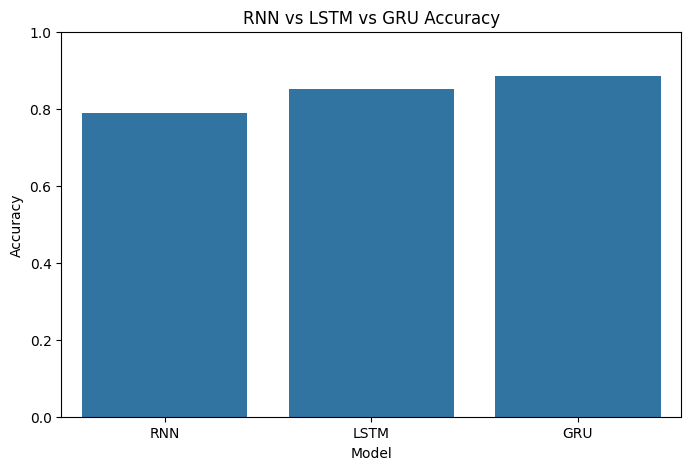

In [15]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x='Model',
    y='Accuracy'
)

plt.title("RNN vs LSTM vs GRU Accuracy")
plt.ylim(0, 1)
plt.show()

In [16]:
rnn_pred = (rnn_model.predict(X_test) >= 0.5).astype(int).flatten()
lstm_pred = (lstm_model.predict(X_test) >= 0.5).astype(int).flatten()
gru_pred = (gru_model.predict(X_test) >= 0.5).astype(int).flatten()

782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step


In [17]:
print("RNN Classification Report")
print(classification_report(y_test, rnn_pred))

print("LSTM Classification Report")
print(classification_report(y_test, lstm_pred))

print("GRU Classification Report")
print(classification_report(y_test, gru_pred))

RNN Classification Report
              precision    recall  f1-score   support

           0       0.76      0.84      0.80     12500
           1       0.82      0.73      0.78     12500

    accuracy                           0.79     25000
   macro avg       0.79      0.79      0.79     25000
weighted avg       0.79      0.79      0.79     25000

LSTM Classification Report
              precision    recall  f1-score   support

           0       0.83      0.89      0.86     12500
           1       0.88      0.81      0.85     12500

    accuracy                           0.85     25000
   macro avg       0.85      0.85      0.85     25000
weighted avg       0.85      0.85      0.85     25000

GRU Classification Report
              precision    recall  f1-score   support

           0       0.88      0.89      0.88     12500
           1       0.89      0.88      0.88     12500

    accuracy                           0.88     25000
   macro avg       0.88      0.88      0.88     2

In [18]:
metrics_df = pd.DataFrame({
    'Model': ['RNN', 'LSTM', 'GRU'],

    'Accuracy': [
        accuracy_score(y_test, rnn_pred),
        accuracy_score(y_test, lstm_pred),
        accuracy_score(y_test, gru_pred)
    ],

    'Precision': [
        precision_score(y_test, rnn_pred),
        precision_score(y_test, lstm_pred),
        precision_score(y_test, gru_pred)
    ],

    'Recall': [
        recall_score(y_test, rnn_pred),
        recall_score(y_test, lstm_pred),
        recall_score(y_test, gru_pred)
    ],

    'F1 Score': [
        f1_score(y_test, rnn_pred),
        f1_score(y_test, lstm_pred),
        f1_score(y_test, gru_pred)
    ]
})

print(metrics_df)

  Model  Accuracy  Precision   Recall  F1 Score
0   RNN   0.78804   0.824516  0.73184  0.775419
1  LSTM   0.85252   0.882741  0.81304  0.846458
2   GRU   0.88440   0.886254  0.88200  0.884122


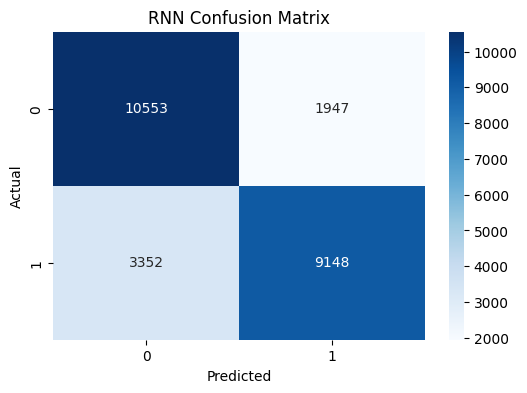

In [19]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix(y_test, rnn_pred),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("RNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

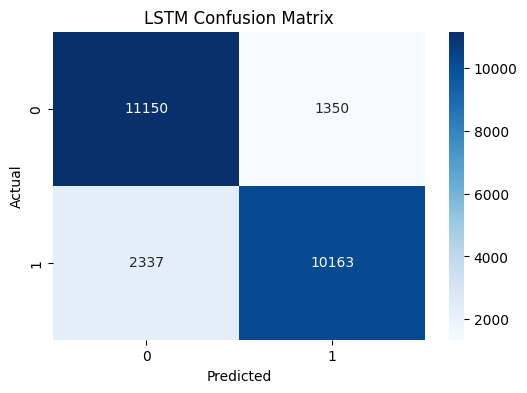

In [20]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix(y_test, lstm_pred),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

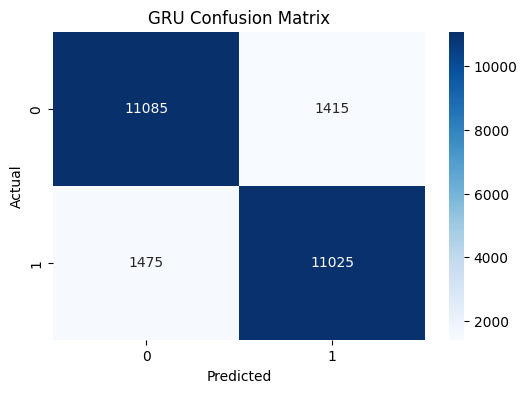

In [21]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix(y_test, gru_pred),
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("GRU Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

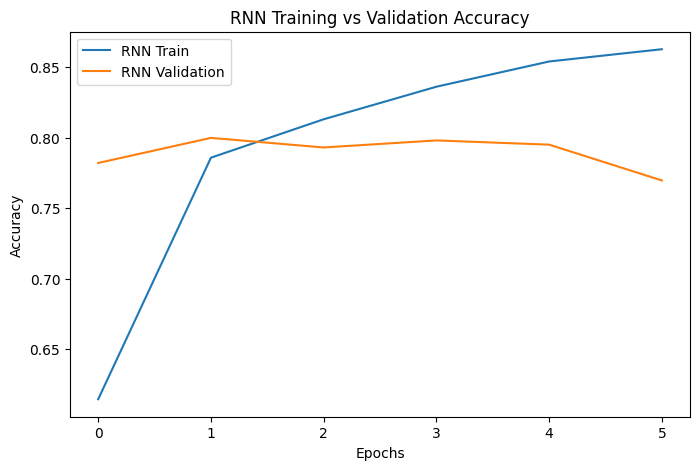

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(rnn_history.history['accuracy'], label='RNN Train')
plt.plot(rnn_history.history['val_accuracy'], label='RNN Validation')

plt.title("RNN Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

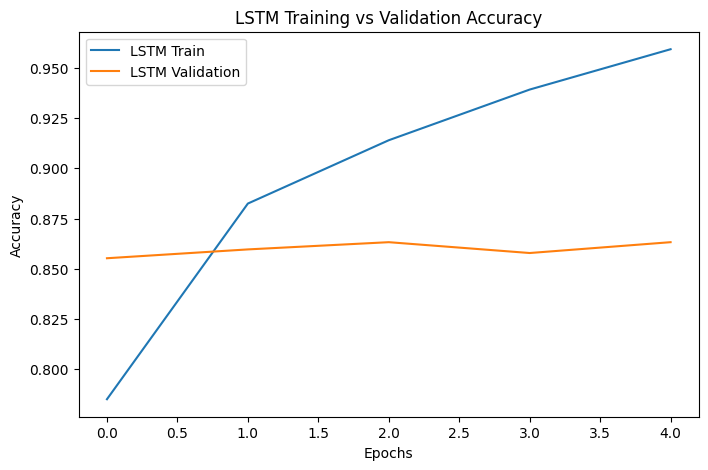

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(lstm_history.history['accuracy'], label='LSTM Train')
plt.plot(lstm_history.history['val_accuracy'], label='LSTM Validation')

plt.title("LSTM Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

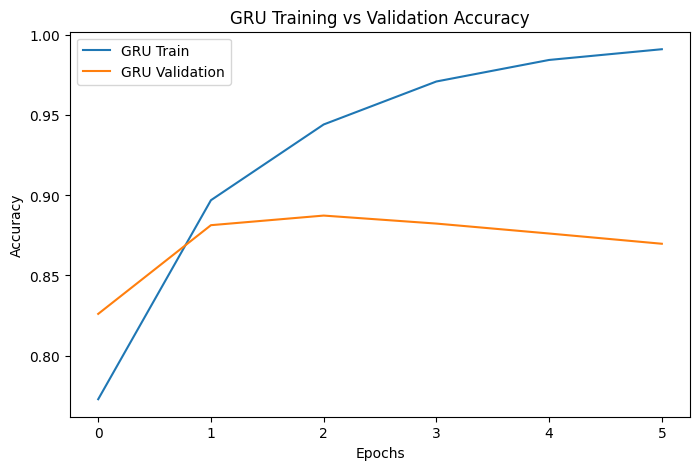

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(gru_history.history['accuracy'], label='GRU Train')
plt.plot(gru_history.history['val_accuracy'], label='GRU Validation')

plt.title("GRU Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [25]:
rnn_model.save("rnn_sentiment_model.keras")

lstm_model.save("lstm_sentiment_model.keras")

gru_model.save("gru_sentiment_model.keras")

print("All Models Saved Successfully!")

All Models Saved Successfully!


In [26]:
from google.colab import files

files.download("gru_sentiment_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>